Device set to use cpu


Columns in your data: ['date', 'year', 'quarter', 'month', 'weekofyear', 'region', 'country', 'city', 'category', 'product', 'channel', 'customer_segment', 'units', 'unit_price', 'discount_rate', 'gross_sales', 'net_sales', 'cogs', 'returns_units', 'returns_value', 'marketing_spend', 'profit', 'campaign', 'is_promo']

Enter your required chart or 'exit' to quit:
Write Python code to visualize profit over the years using a bar chart. Use ‘year’ on the x-axis and ‘profit’ on the y-axis, loading data from sales.csv. Make sure the code includes:  All required imports (pandas, matplotlib.pyplot).  Safe numeric conversion for ‘year’ and ‘profit’.  Dropping rows with missing values.  Sorting data by year before plotting.  A clear title, axis labels, and grid.  A figure size for readability. Return only the complete final code.

Generated Code:

import pandas as pd
import matplotlib.pyplot as plt
# Load data from CSV file into DataFrame
df = pd.read_csv('sales.csv')
# Filter out rows with miss

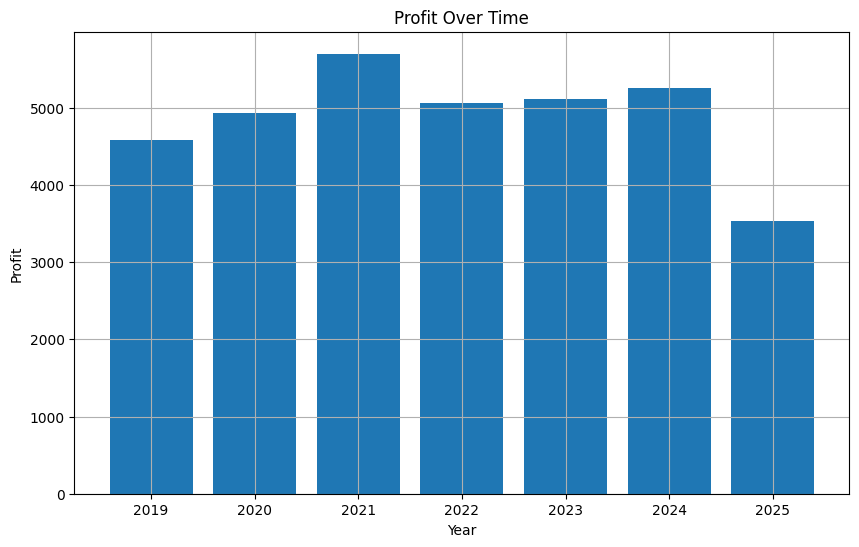


Chart rendered successfully.


Enter your required chart or 'exit' to quit:
Write Python code to visualize profit by region using a bar chart. Load the data from sales.csv. Use ‘region’ on the x-axis and ‘profit’ on the y-axis. Make sure the code includes:  All required imports (pandas, matplotlib.pyplot).  Safe numeric conversion for ‘profit’.  Dropping rows with missing values.  Grouping data by region and summing profit.  Sorting regions by total profit.  A figure size, clear labels, title, and grid. Return only the complete final code.

Generated Code:

import pandas as pd
# Load the dataset
df = pd.read_csv('sales.csv')
# Display the first few rows of the dataframe
print(df.head())
# Calculate the total profit for each region
total_profit_by_region = df.groupby('region')['profit'].sum()
# Create a bar chart showing the total profit by region
plt.figure(figsize=(10,6))
plt.bar(total_profit_by_region.index, total_profit_by_region.values)
plt.xlabel('Region')
plt.ylabel('Total Profi

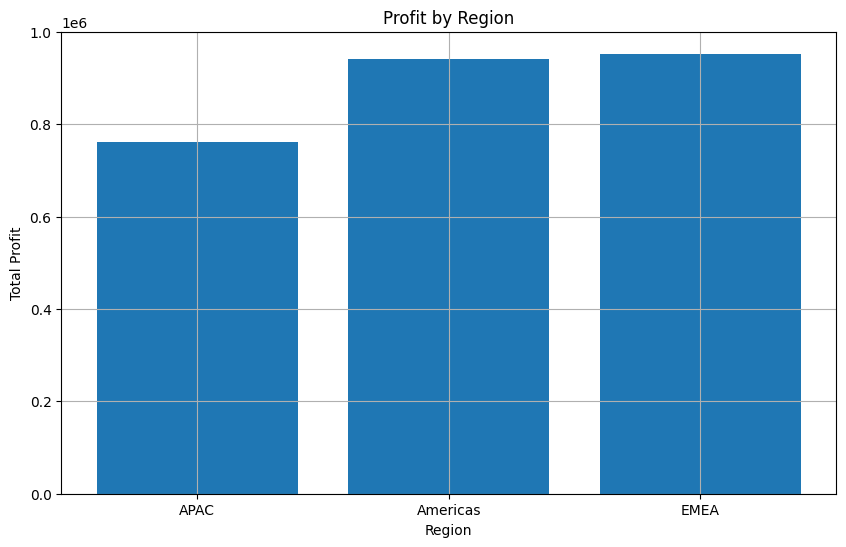


Chart rendered successfully.


Enter your required chart or 'exit' to quit:
Write Python code to visualize profit by category using a pie chart. Load the data from sales.csv. Use ‘category’ for the labels and ‘profit’ for the values. Make sure the code includes:  All required imports (pandas, matplotlib.pyplot).  Safe numeric conversion for ‘profit’.  Dropping rows with missing values.  Grouping data by category and summing profit.  A clear title and readable labels.  Displaying percentages on the pie chart. Return only the complete final code.

Generated Code:

import pandas as pd
import numpy as np
# Load the dataset
df = pd.read_csv('sales.csv')
# Convert 'profit' column to float type
df['profit'] = df['profit'].astype(float)
# Calculate total profit across all categories
total_profit = df.groupby('category')['profit'].sum().reset_index()
# Create a pie chart showing the distribution of profits by category
plt.figure(figsize=(8, 6))
plt.pie(total_profit['profit'], labels=total_prof

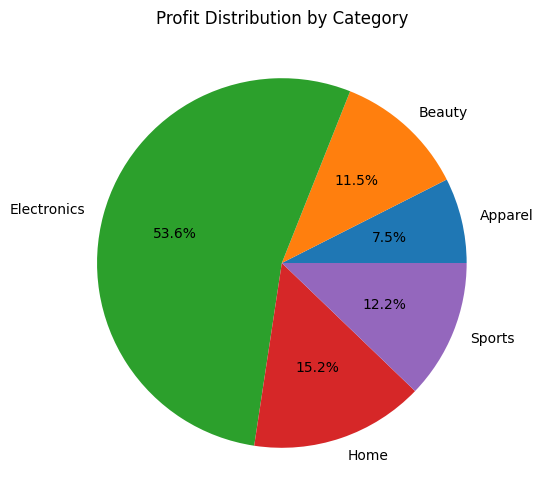


Chart rendered successfully.


Enter your required chart or 'exit' to quit:
exit
Exiting.


In [ ]:
!pip install transformers accelerate --quiet

from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import torch
import pandas as pd
import matplotlib.pyplot as plt
import traceback
import time

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=300,
    temperature=0.2
)

df = pd.read_csv("sales.csv")
columns = list(df.columns)
print("Columns in your data:", columns)

def get_chart_code(prompt, columns):
    full_prompt = (
        "You are a senior Data Visualization Engineer. "
        "Generate ONLY one block of clean Python code for a chart using pandas and matplotlib.\n\n"

        "Dataset information:\n"
        "CSV filename: 'sales.csv'\n"
        f"Columns: {columns}\n\n"

        "=== STRICT RULES ===\n"
        "Output ONLY Python code.\n"
        "NO explanations.\n"
        "NO bullet points.\n"
        "NO text before or after the code.\n"
        "NO markdown.\n"
        "NO comments.\n\n"

        f"Task: {prompt}"
    )

    raw = generator(full_prompt)[0]["generated_text"]


    lines = raw.splitlines()
    cleaned = []
    keep = False

    for line in lines:
        stripped = line.strip()

        if stripped.startswith("import") or stripped.startswith("from"):
            keep = True

        if keep:
            if stripped.startswith(("•", "-", "*", "```", ">")):
                continue
            if "Output ONLY" in stripped:
                continue
            if stripped == "":
                continue

            cleaned.append(line)


        if "plt.show()" in stripped:
            break

    return "\n".join(cleaned)

def run_generated_code(code: str, scope: dict):
    try:
        exec(compile(code, "<llm_plot>", "exec"), scope)
        print("\nChart rendered successfully.\n")
    except Exception:
        print("\nError while running chart code:\n")
        print(traceback.format_exc())

while True:
    try:
        user_prompt = input("\nEnter your required chart or 'exit' to quit:\n")
    except EOFError:
        print("\nInput interrupted. Restarting prompt...\n")
        continue

    if user_prompt.strip().lower() == "exit":
        print("Exiting.")
        break

    code = get_chart_code(user_prompt, columns)

    print("\nGenerated Code:\n")
    print(code)

    scope = {
        "pd": pd,
        "plt": plt,
        "df": df
    }

    run_generated_code(code, scope)

    plt.close('all')
    time.sleep(0.1)


original prompt : You are a senior Data Visualization Engineer and your task is to generate only one block of clean Python code for a chart using pandas and matplotlib. The dataset information is as follows: the CSV filename is 'sales.csv' and the columns are given by {columns}. You must follow strict rules: output only Python code with no explanations, no bullet points, no text before or after the code, no markdown, and no comments. The specific task is: {prompt}.

reason & technique : I use role-playing so the model behaves like a senior Data Visualization Engineer and produces expert, consistent code. I use this method to ensure it outputs only one block of clean Python code using pandas and matplotlib. I use the dataset from 'sales.csv' with the columns in {columns}. To make models like Qwen2.5 follow instructions strictly, I use clear rules: output only Python code with no explanations, markdown, comments, bullet points, or extra text. I use these constraints to ensure the final answer is only the Python code needed for the task: {prompt}.

prompt 1 : Write Python code to visualize total profit per year using a bar chart from sales.csv. Steps to follow:  Load the data and include all necessary imports (pandas, matplotlib.pyplot).  Convert ‘year’ and ‘profit’ columns to numeric safely.  Drop rows with missing values in these columns.  Group the data by ‘year’ and sum the profit for each year.  Sort the years in ascending order.  Plot the aggregated profit as a bar chart with ‘year’ on the x-axis and total ‘profit’ on the y-axis.  Include a figure size, clear title, axis labels, and a grid. Return only the complete, final code.

Feedback & reason 1 : I visualized total yearly profit to show how profitability changes over time. A bar chart is effective here because it makes year-to-year comparisons easy. Grouping, summing, and sorting the profit ensures the chart is accurate and clearly structured.

Prompt 2 : Write Python code to visualize profit by region using a bar chart. Load the data from sales.csv. Use ‘region’ on the x-axis and ‘profit’ on the y-axis. Make sure the code includes:  All required imports (pandas, matplotlib.pyplot).  Safe numeric conversion for ‘profit’.  Dropping rows with missing values.  Grouping data by region and summing profit.  Sorting regions by total profit.  A figure size, clear labels, title, and grid. Return only the complete final code.

Feedback & reason 2 : This prompt focuses on comparing profit across regions. A bar chart works well because it highlights which regions perform best. Grouping and summing profit by region provides a clear view of regional differences.

Prompt 3 : Write Python code to visualize total profit per category using a pie chart from sales.csv. Steps to follow:  Load the data and include all necessary imports (pandas, matplotlib.pyplot).  Convert the ‘profit’ column to numeric safely.  Drop rows with missing values in ‘category’ or ‘profit’.  Group the data by ‘category’ and sum the profit for each category.  Plot the aggregated profit as a pie chart, using ‘category’ as labels and showing percentages.  Include a clear title and readable labels. Return only the complete, final code.

Feedback & reason 3 : This visualization examines how product categories contribute to total profit. A pie chart is suitable because it shows the proportional share of each category. Summing the profit by category gives a straightforward view of category dominance.